In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/telco_clean.csv")
sns.set_theme(style="whitegrid")

In [21]:
df["ChurnPercentage"] = df["Churn"] * 100

In [22]:
churn_rate = (df['Churn'].mean())*100
retention_rate= 100 - churn_rate
print(f"Overall churn_rate {churn_rate:.2f}%")
print(f"Overall retention_rate {retention_rate:.2f}%")
Rate= pd.DataFrame({"Customer Status":["Retained","Churned"],"Percentage":[retention_rate,churn_rate]})
print(Rate)

Overall churn_rate 26.54%
Overall retention_rate 73.46%
  Customer Status  Percentage
0        Retained   73.463013
1         Churned   26.536987


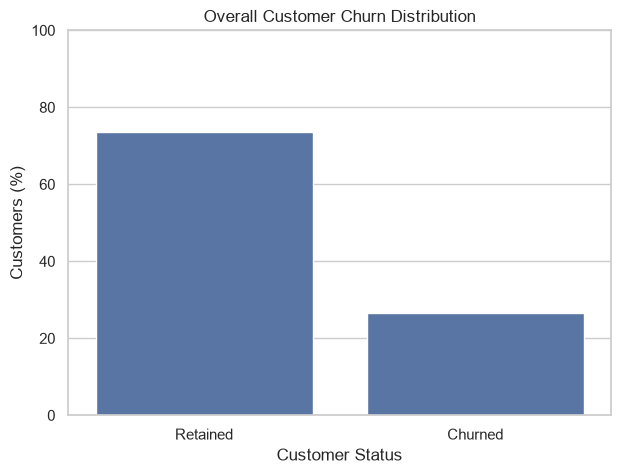

In [23]:
plt.figure(figsize=(7,5))
sns.barplot(data=Rate, x='Customer Status', y='Percentage')
plt.title("Overall Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Customers (%)")
plt.ylim(0, 100)
plt.savefig("../reports/figures/overall_churn.png", dpi=150, bbox_inches="tight")
plt.show()

Observation: Approximately 26.54% of customers have churned, while 73.46% have been retained. This indicates that roughly one in four customers leaves the telecom service.

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64


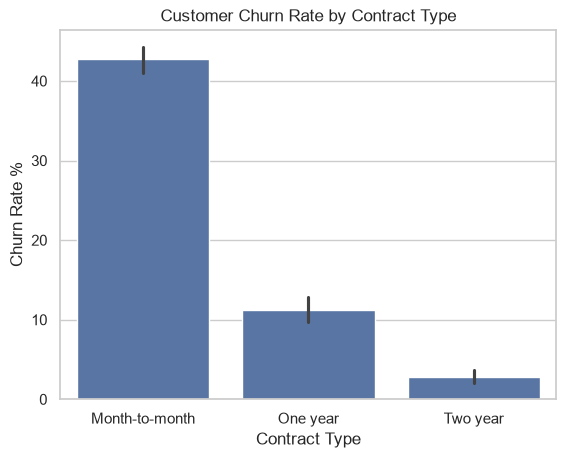

In [24]:
contract_churn=df.groupby("Contract")["Churn"].mean() * 100
print(contract_churn)
sns.barplot(data=df, x='Contract', y='ChurnPercentage')
plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate %")
plt.savefig("../reports/figures/churn_by_contract.png", dpi=150, bbox_inches="tight")
plt.show()


**Observation:** Month-to-month contract customers have the highest churn rate at 42.71%, followed by one-year contract customers at 11.27%. Two-year contract customers have the lowest churn rate at just 2.83%.

**Business Insight:** Customers on month-to-month contracts appear to be at significantly higher risk of churning. The telecom company could prioritize these customers for targeted retention campaigns and explore ways to encourage longer-term contracts through suitable offers and incentives.

In [25]:
df["TenureGroup"]=pd.cut(df['tenure'], bins=[-1, 12, 24, 48, float("inf")],labels=["0-12", "13-24", "25-48", "49+"], )
print(df["TenureGroup"].value_counts())
print(df["TenureGroup"].isna().sum())
tenure_churn=(df.groupby("TenureGroup")["Churn"].mean() * 100).sort_index()
print('Tenure churn: ',tenure_churn)

TenureGroup
49+      2239
0-12     2186
25-48    1594
13-24    1024
Name: count, dtype: int64
0
Tenure churn:  TenureGroup
0-12     47.438243
13-24    28.710938
25-48    20.388959
49+       9.513176
Name: Churn, dtype: float64


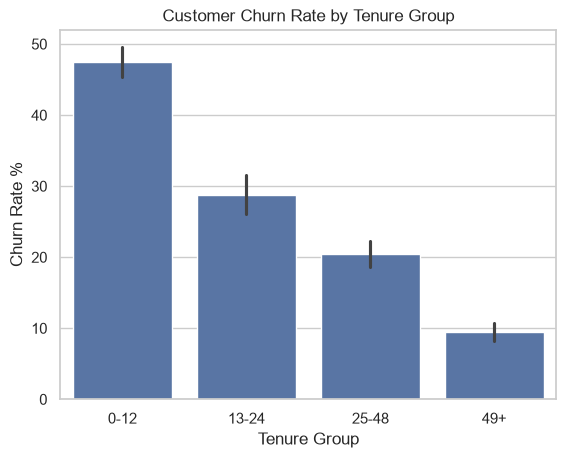

In [26]:
sns.barplot(data=df, x='TenureGroup', y='ChurnPercentage')
plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate %")
plt.savefig("../reports/figures/churn_by_tenure.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** Customers with 0–12 months of tenure have the highest churn rate (47.44%), while customers with 49+ months have the lowest (9.51%). This suggests that the first year is a critical period for customer retention.

**Business Insight:** The telecom company could prioritize early customer engagement, onboarding support, and proactive retention campaigns during the first year. Since month-to-month contracts also show particularly high churn (42.71%), these customers deserve attention as well.

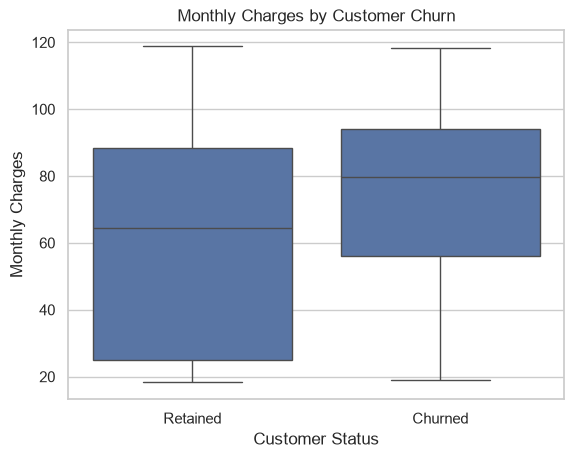

In [27]:
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title("Monthly Charges by Customer Churn")
plt.xlabel("Customer Status")
plt.ylabel("Monthly Charges")
plt.xticks(ticks=[0,1],labels=['Retained','Churned'])
plt.savefig("../reports/figures/monthly_charges_by_churn.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
print(df.groupby("Churn")["MonthlyCharges"].describe())

        count       mean        std    min    25%     50%   75%     max
Churn                                                                  
0      5174.0  61.265124  31.092648  18.25  25.10  64.425  88.4  118.75
1      1869.0  74.441332  24.666053  18.85  56.15  79.650  94.2  118.35


**Observation:** Churned customers have a higher median monthly charge (approximately 80) compared to retained customers (approximately 65). The middle 50% of churned customers also generally have higher monthly charges than retained customers.

**Business Insight:** Higher monthly charges appear to be associated with customer churn. The telecom company could investigate pricing concerns and perceived service value, particularly among higher-paying customers, and consider targeted retention offers. However, this analysis shows an association and does not establish that higher charges cause customers to churn.

InternetService
DSL            18.959108
Fiber optic    41.892765
No              7.404980
Name: Churn, dtype: float64


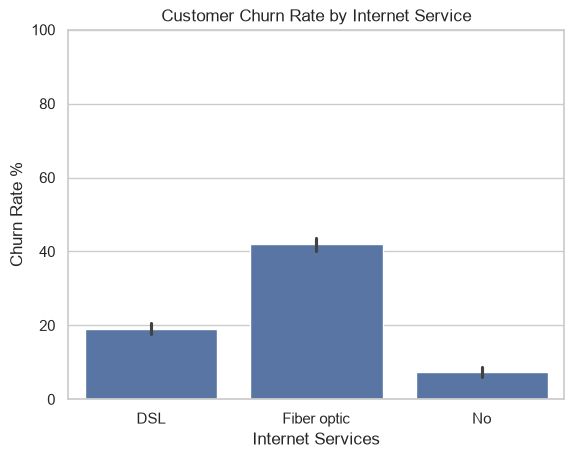

In [29]:
internet_churn=df.groupby("InternetService")["Churn"].mean() * 100
print(internet_churn.sort_index())
sns.barplot(data=df, x='InternetService', y='ChurnPercentage')
plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Internet Services")
plt.ylabel("Churn Rate %")
plt.ylim(0, 100)
plt.show()


Fiber optic customers have the highest churn rate at 41.89%, more than twice the rate of DSL customers.

This is interesting because fiber optic is generally a higher-tier internet service. Whether pricing, service quality, or customer expectations should be investigated to check is these could be contributing factors. The data alone doesn't establish the reason.

TechSupport
No                     41.635474
No internet service     7.404980
Yes                    15.166341
Name: Churn, dtype: float64


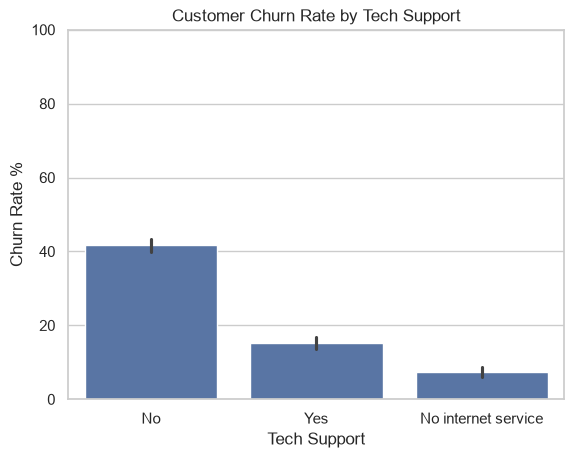

In [30]:
tech_support_churn=df.groupby("TechSupport")["Churn"].mean() * 100
print(tech_support_churn.sort_index())
sns.barplot(data=df, x='TechSupport', y='ChurnPercentage')
plt.title("Customer Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Churn Rate %")
plt.ylim(0, 100)
plt.savefig("../reports/figures/churn_by_internet_service.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** Customers without Tech Support have a considerably higher churn rate (approximately 41%) compared to customers who have Tech Support (approximately 15%). Customers without internet service have the lowest churn rate at approximately 7%.

**Business Insight:** The telecom company could prioritize customers who do not have Tech Support for proactive engagement and support-related retention campaigns. It may also investigate whether support availability and customer satisfaction are associated with churn. This analysis shows association, not causation.

OnlineSecurity
No                     41.766724
No internet service     7.404980
Yes                    14.611194
Name: Churn, dtype: float64


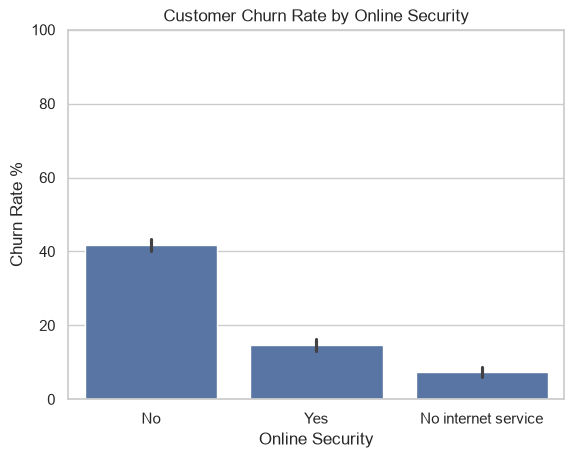

In [31]:
online_security_churn=df.groupby("OnlineSecurity")["Churn"].mean() * 100
print(online_security_churn.sort_index())
sns.barplot(data=df, x='OnlineSecurity', y='ChurnPercentage')
plt.title("Customer Churn Rate by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Churn Rate %")
plt.ylim(0, 100)
plt.savefig("../reports/figures/churn_by_tech_support.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** Customers without Online Security have a considerably higher churn rate (approximately 41.8%) compared to customers with Online Security (approximately 14.6%). Customers without internet service have the lowest churn rate at approximately 7.4%.

**Business Insight:** Customers without Online Security could be prioritized for targeted retention campaigns. The telecom company could investigate whether security needs, service satisfaction, or perceived value are associated with churn and explore suitable security service offers. However, this analysis shows an association and does not prove that the absence of Online Security causes customers to churn.

Index(['Electronic check', 'Mailed check', 'Bank transfer (automatic)',
       'Credit card (automatic)'],
      dtype='str', name='PaymentMethod')


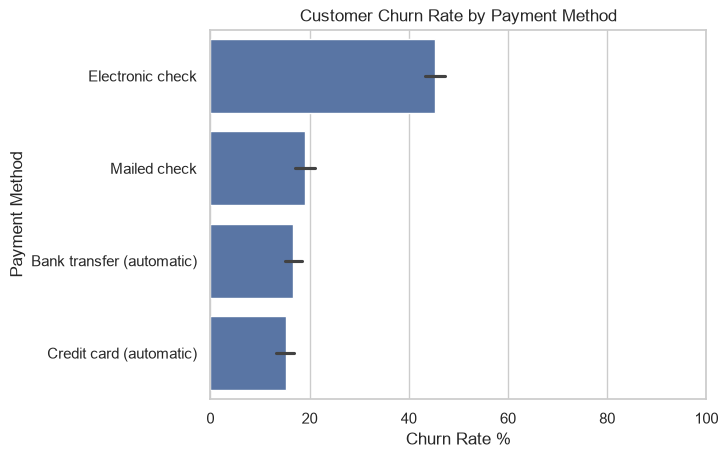

In [32]:
payment_method_churn=df.groupby("PaymentMethod")["Churn"].mean() * 100
print(payment_method_churn.sort_values(ascending=False).index)
sns.barplot(data=df, x='ChurnPercentage', y='PaymentMethod', order=payment_method_churn.sort_values(ascending=False).index)
plt.title("Customer Churn Rate by Payment Method")
plt.ylabel("Payment Method")
plt.xlabel("Churn Rate %")
plt.xlim(0, 100)
plt.savefig("../reports/figures/churn_by_online_security.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** Customers using electronic checks have the highest churn rate (approximately 45%), while customers using automatic payment methods have comparatively lower churn rates. Mailed check customers also show a higher churn rate than customers using automatic payments.

**Business Insight:** The telecom company could investigate why electronic check users are more likely to churn and consider encouraging convenient automatic payment options through customer education or suitable incentives. However, payment method alone does not establish the reason for churn.

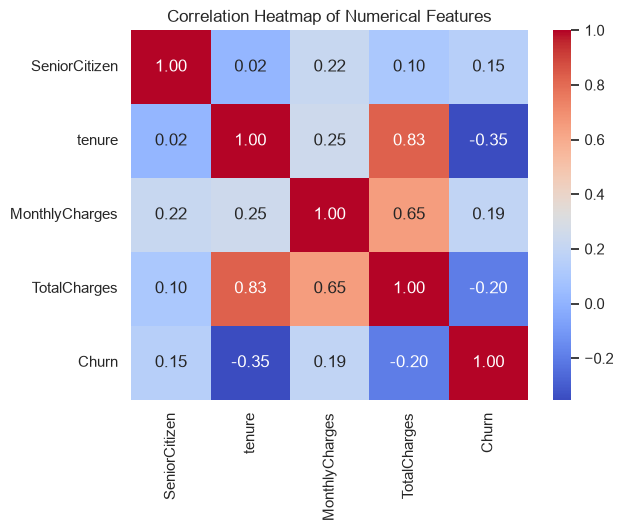

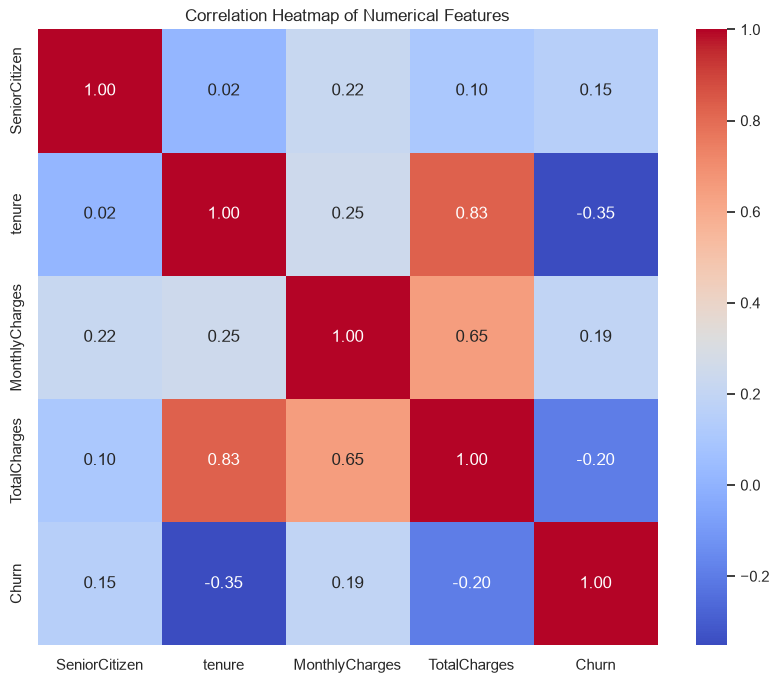

In [33]:
correlation_matrix=(df.select_dtypes(include='number').drop(columns=["ChurnPercentage"]).corr())
sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm',fmt='.2f')
plt.title("Correlation Heatmap of Numerical Features")
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Features")
plt.savefig("../reports/figures/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### Correlation Heatmap — Key Observations

**Observation:**

- **Tenure vs Churn (-0.35):** Shows a moderate negative correlation, suggesting that customers with longer tenure tend to have lower churn rates.
- **MonthlyCharges vs Churn (+0.19):** Shows a weak positive correlation, indicating that higher monthly charges are slightly associated with churn.
- **TotalCharges vs Churn (-0.20):** Shows a weak negative correlation, suggesting that customers with higher accumulated charges tend to have lower churn rates.
- **Tenure vs TotalCharges (+0.83):** Shows a strong positive correlation, as customers who stay longer generally accumulate higher total charges.

**Business Insight:**

Tenure shows the strongest absolute correlation with churn among the numerical features examined. This supports the earlier finding that newer customers are more likely to churn. Monthly charges also show a weak positive relationship with churn and may be worth investigating further.

**Note:** Correlation measures association between numerical variables and does not establish causation. These findings will help guide further statistical analysis and model development.

## Key Findings

1. **Overall Churn:** Approximately 26.54% of customers have churned, indicating a significant customer retention challenge.

2. **Contract Type:** Month-to-month customers have the highest churn rate (42.71%), compared to one-year (11.27%) and two-year contracts (2.83%).

3. **Customer Tenure:** Customers with 0–12 months of tenure have the highest churn rate (47.44%), while customers with 49+ months have the lowest (9.51%). This highlights the importance of early customer retention.

4. **Monthly Charges:** Churned customers have a higher median monthly charge (approximately 80) than retained customers (approximately 65), suggesting a possible relationship between monthly costs and churn.

5. **Additional Services:** Customers without Tech Support and Online Security show considerably higher churn rates than customers who have these services.

6. **Payment Method:** Customers using electronic checks have the highest churn rate (approximately 45%), while automatic payment methods show comparatively lower churn rates.

**Overall Conclusion:** Customer churn is associated with several factors, including contract type, tenure, monthly charges, additional services, and payment method. These findings will guide feature selection, statistical testing, and predictive model development.

*Note: These are exploratory findings based on observed associations and do not establish causation.*